> **Next research experiment:** [Laya V5 — activation-aware accuracy-first Colab](https://colab.research.google.com/github/vtavakkoli/TinyCeNN-LM/blob/main/notebooks/Laya_1p2_All28_ActivationAware_AccuracyFirst_V5_Colab.ipynb) is based on V4's failed 98.96% independent audit. V4 remains unchanged as a reproducible baseline.\n\n# Laya V4 — All 28 Layers: Mixed-Bit + Sparse Residual Accuracy Recovery

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vtavakkoli/TinyCeNN-LM/blob/main/notebooks/Laya_1p2_All28_MixedBit_SparseRecovery_V4_Colab.ipynb)

**Source:** [vtava/Laya-1.2-speedup-standalone-fp16](https://huggingface.co/vtava/Laya-1.2-speedup-standalone-fp16). Experiment leaves this source untouched.

The uploaded Tesla T4 V3 results show **112/112 projections quantized** (100 INT8, 8 INT4, 4 ternary), **42.48% smaller packed state** (803.05 → 461.88 MiB), **99.22% DEV versus 97.27% AUDIT agreement**, and **0.97× end-to-end speed at B4 × 512**. Cached FP16 weights plus packed buffers consumed 1571 MiB.

**V4 fixes the weak points:** start with all 28 layers quantized at INT8 plus sparse per-output outlier-error compensation; improve sensitive modules; then selectively test INT4 and optional ternary, with quality gates. Audit and official test stay sealed until after selection.

V4 also benchmarks (a) packed weights with FP16 caches and (b) native FP16 reconstruction with packed GPU buffers discarded. PyTorch SDPA remains the attention operator and native FP16 `F.linear` runs projections. **No native 2-bit speedup is assumed**.

The compressed delta is experimental and requires the *exact* original FP16 checkpoint revision to reload.


In [1]:
#@title 1. Install dependencies (native PyTorch SDPA; no custom Triton requirement)
%pip -q install "transformers==4.57.6" "huggingface_hub>=0.25,<1" "safetensors>=0.4" "datasets>=2.20,<5" pandas matplotlib


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 76.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 15.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 64.8 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.29.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [2]:
#@title 2. Configure and download original FP16 standalone model
import sys, os, gc, json, random, math, time, zipfile, inspect, importlib.util
from collections import Counter
from pathlib import Path
import numpy as np, pandas as pd, torch
from torch import nn
from torch.nn import functional as F
from huggingface_hub import snapshot_download
from IPython.display import display

SOURCE_REPO="vtava/Laya-1.2-speedup-standalone-fp16" #@param {type:"string"}
TRAIN_CASES=1200 #@param {type:"integer"}
DEV_DECISIONS=384 #@param {type:"integer"}
AUDIT_DECISIONS=384 #@param {type:"integer"}
OFFICIAL_TEST_DECISIONS=400 #@param {type:"integer"}
MAX_LEN=512 #@param {type:"integer"}
BATCH_SIZE=4 #@param {type:"integer"}
MIN_DEV_AGREEMENT=0.992 #@param {type:"number"}
MIN_AUDIT_AGREEMENT=0.99 #@param {type:"number"}
MAX_MEAN_JS=0.0015 #@param {type:"number"}
BENCH_REPEATS=8 #@param {type:"integer"}
MIN_LINEAR_ELEMENTS=4096 #@param {type:"integer"}
INITIAL_SPARSE_K=16 #@param {type:"integer"}
RESCUE_SPARSE_K=48 #@param {type:"integer"}
MAX_RESCUE_TRIALS=48 #@param {type:"integer"}
INT4_SPARSE_K=24 #@param {type:"integer"}
TRY_TERNARY=False #@param {type:"boolean"}
TERNARY_SPARSE_K=48 #@param {type:"integer"}
VERIFY_PACKED_RELOAD=True #@param {type:"boolean"}
SAVE_PACKED_DELTA=True #@param {type:"boolean"}
SEED=2033
OUT=Path("/content/Laya_All28_MixedBit_Sparse_V4")
OUT.mkdir(parents=True,exist_ok=True)
random.seed(SEED);np.random.seed(SEED);torch.manual_seed(SEED)
assert torch.cuda.is_available(), "Select T4 / L4 GPU in Colab Runtime settings."
assert torch.cuda.get_device_capability()[0]>=7, "Tensor-core GPU required."
try:
    from google.colab import userdata
    HF_TOKEN=userdata.get("HF_TOKEN")
except Exception:
    HF_TOKEN=os.environ.get("HF_TOKEN")
from huggingface_hub import HfApi
SOURCE_REVISION=HfApi(token=HF_TOKEN).model_info(SOURCE_REPO).sha
ROOT=Path(snapshot_download(repo_id=SOURCE_REPO,revision=SOURCE_REVISION,token=HF_TOKEN))
print("Pinned base model revision:",SOURCE_REVISION)
CFG=json.loads((ROOT/"config.json").read_text())
assert CFG.get("format")=="laya-1p2-full-standalone-v1"
assert CFG.get("dtype_on_disk")=="float16"
print("GPU:",torch.cuda.get_device_name(0),"| input length:",MAX_LEN)
print("Loaded original checkpoint files:",len(list(ROOT.iterdir())))


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:104: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

.gitattributes: 0.00B [00:00, ?B/s]

config.json: 0.00B [00:00, ?B/s]

SOURCE_REVISIONS.json:   0%|          | 0.00/578 [00:00<?, ?B/s]

...

size_report.json: 0.00B [00:00, ?B/s]

requirements.txt:   0%|          | 0.00/74.0 [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

Pinned base model revision: 2891f7312d8e7c65b43a6e04c29cc226b06b4fac
GPU: Tesla T4 | input length: 512
Loaded original checkpoint files: 11


In [3]:
#@title 3. Load the exact LayaStandalone architecture and request PyTorch SDPA
def import_module(file,name):
    spec=importlib.util.spec_from_file_location(name,str(file))
    if spec is None or spec.loader is None:raise ImportError(str(file))
    m=importlib.util.module_from_spec(spec)
    sys.modules[name]=m
    spec.loader.exec_module(m)
    return m

source=import_module(ROOT/"modeling_laya_standalone.py","_laya_standalone_forced_v3")
teacher,tokenizer=source.load_model(ROOT,device="cpu",
                                  local_files_only=True,compile_head=False)
teacher=teacher.to("cuda",dtype=torch.float16).eval().requires_grad_(False)
teacher.encoder.config.reference_compile=False
try:
    if hasattr(teacher.encoder,"set_attn_implementation"):
        teacher.encoder.set_attn_implementation("sdpa")
    else:
        teacher.encoder.config._attn_implementation="sdpa"
except Exception as error:
    print("Original SDPA path retained:",str(error)[:180])
torch.backends.cuda.enable_flash_sdp(True)
torch.backends.cuda.enable_mem_efficient_sdp(True)
torch.backends.cuda.enable_math_sdp(True)
assert hasattr(teacher.encoder,"layers")
N_LAYERS=len(teacher.encoder.layers)
print("Discovered",N_LAYERS,"encoder layers")
assert N_LAYERS==28, f"This forced-all-28 notebook expects exactly 28; got {N_LAYERS}"
print("Original parameter count:",sum(p.numel() for p in teacher.parameters()))


Discovered 28 encoder layers
Original parameter count: 421029889


In [4]:
#@title 4. Load pinned all-layer sparse residual G128 quantizer; numerical preflight
from urllib.request import urlopen
RUNTIME_REV="26a994aa45e838a90fd5b37a6be3b73efc972085"
file_name="laya_mixedbit_sparse_v4.py"
raw=f"https://raw.githubusercontent.com/vtavakkoli/TinyCeNN-LM/{RUNTIME_REV}/src/tinycenn_lm/{file_name}"
local=Path("/content")/file_name
with urlopen(raw,timeout=90) as response: local.write_bytes(response.read())
assert local.stat().st_size>9000
q=import_module(local,"laya_mixedbit_sparse_v4")
from safetensors.torch import save_file,load_file
for bits,k in ((2,24),(4,24),(8,16)):
    linear=nn.Linear(191,129,device="cuda",dtype=torch.float16)
    packed=q.PackedSparseLinear.from_linear(linear,bits,k)
    xx=torch.randn(11,191,device="cuda",dtype=torch.float16)
    decoded=q.unpack_codes(packed.packed_weight,bits,packed.padded)
    assert torch.equal(q.pack_codes(decoded,bits),packed.packed_weight)
    with torch.inference_mode():
        a=F.linear(xx,packed.weight_fp16(),packed.bias)
        b=packed(xx)
        d=packed.to_native_fp16()(xx)
    torch.testing.assert_close(a,b,atol=0.01,rtol=0.01)
    torch.testing.assert_close(b,d,atol=0.01,rtol=0.01)
    print(bits,"bit sparse-k",k,"GPU native FP16 parity PASS")
    del linear,packed,xx
gc.collect();torch.cuda.empty_cache()


2 bit sparse-k 24 GPU native FP16 parity PASS
4 bit sparse-k 24 GPU native FP16 parity PASS
8 bit sparse-k 16 GPU native FP16 parity PASS


In [5]:
#@title 5. Build disjoint real typed-decision DEV / AUDIT data from the train split
from datasets import load_dataset
def parse_json(value):
    if isinstance(value,str):
        try:return json.loads(value)
        except Exception:return value
    return value

def prepare_items(rows,target):
    groups=[]
    for row in rows:
        state=parse_json(row.get("state"))
        questions=parse_json(row.get("questions"))
        if not isinstance(questions,dict):continue
        case=[]
        for question in questions.values():
            try:
                normalized=source.normalize_question(parse_json(question))
                ids,markers=source.build_sequence(
                    tokenizer,state,normalized,max_len=MAX_LEN,
                    head_max_len=192,truncate_left=isinstance(state,list))
                if len(markers)<2:continue
                case.append(dict(ids=ids,markers=markers,qtype=source.QTYPES[normalized["t"]]))
            except (TypeError,ValueError,KeyError,IndexError):
                continue
        if case:groups.append(case)
    # Round-robin cases instead of grabbing many questions from a few cases.
    result=[]
    for k in range(max(map(len,groups),default=0)):
        for case in groups:
            if k<len(case):
                result.append(case[k])
                if len(result)>=target:return result
    return result

rows=list(load_dataset("LocalLLaMA/typed-decisions","all",split=f"train[:{TRAIN_CASES}]"))
random.Random(SEED).shuffle(rows)
mid=len(rows)//2
DEV_ITEMS=prepare_items(rows[:mid],DEV_DECISIONS)
AUDIT_ITEMS=prepare_items(rows[mid:],AUDIT_DECISIONS)
if len(DEV_ITEMS)<DEV_DECISIONS or len(AUDIT_ITEMS)<AUDIT_DECISIONS:
    raise RuntimeError(f"Not enough disjoint real decisions: dev={len(DEV_ITEMS)}, audit={len(AUDIT_ITEMS)}")

def batchify(items,size=BATCH_SIZE,pad_len=None):
    batches=[]
    for offset in range(0,len(items),size):
        b=source.collate_items(items[offset:offset+size],int(tokenizer.pad_token_id))
        if pad_len is not None:
            missing=pad_len-b["input_ids"].shape[1]
            if missing<0:raise ValueError(f"Sequence too long for fixed bench length {pad_len}")
            b["input_ids"]=F.pad(b["input_ids"],(0,missing),value=int(tokenizer.pad_token_id))
            b["attention_mask"]=F.pad(b["attention_mask"],(0,missing))
        batches.append({key:t.cuda() for key,t in b.items()})
    return batches

DEV=batchify(DEV_ITEMS)
AUDIT=batchify(AUDIT_ITEMS)
print("Disjoint decisions",len(DEV_ITEMS),"development,",len(AUDIT_ITEMS),"audit")


README.md: 0.00B [00:00, ?B/s]

all/train-00000-of-00001.parquet:   0%|          | 0.00/599k [00:00<?, ?B/s]

all/test-00000-of-00001.parquet:   0%|          | 0.00/222k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/1200 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/400 [00:00<?, ? examples/s]

Disjoint decisions 384 development, 384 audit


In [6]:
#@title 6. Capture teacher logits and compute stable agreement / JS for real options
@torch.inference_mode()
def infer(model,b):
    with torch.autocast("cuda",dtype=torch.float16):
        z=model(**b)
    return z[0] if isinstance(z,(tuple,list)) else z

@torch.inference_mode()
def capture(model,batches):
    return [infer(model,b).detach().float().cpu() for b in batches]
DEV_TEACHER=capture(teacher,DEV)
AUDIT_TEACHER=capture(teacher,AUDIT)

@torch.inference_mode()
def compare(model,batches,truth):
    count=hits=0;total_js=0.0
    max_l1=0.0
    for b,logits in zip(batches,truth):
        pred=infer(model,b).detach().float().cpu()
        mask=b["marker_mask"].cpu()
        pred=pred.masked_fill(~mask,-1e4)
        ref=logits.masked_fill(~mask,-1e4)
        probs=pred.softmax(-1).clamp_min(1e-9)
        target=ref.softmax(-1).clamp_min(1e-9)
        mix=0.5*(probs+target)
        js=0.5*(probs*(probs/mix).log()).sum(-1)
        js+=0.5*(target*(target/mix).log()).sum(-1)
        count+=len(pred)
        hits+=int((probs.argmax(-1)==target.argmax(-1)).sum())
        total_js+=float(js.sum())
        max_l1=max(max_l1,float((pred-ref).abs().max()))
    return dict(n=count,agreement=hits/count,mean_js=total_js/count,max_logit_abs=max_l1)

def quality_ok(m):
    return m["agreement"]>=MIN_DEV_AGREEMENT and m["mean_js"]<=MAX_MEAN_JS
print("Teacher self-check:",compare(teacher,DEV,DEV_TEACHER))

def quality_better(a,b):
    return (a["agreement"],-a["mean_js"])>(b["agreement"],-b["mean_js"])


Teacher self-check: {'n': 384, 'agreement': 1.0, 'mean_js': 0.0, 'max_logit_abs': 0.0}


In [7]:
#@title 7. Force 8-bit + sparse correction into ALL 112 encoder projections
import copy
student=copy.deepcopy(teacher).eval().requires_grad_(False)
original_state_bytes=q.state_bytes(teacher)
selected_bits={}
selected_sparse={}
names=[]
for layer in range(N_LAYERS):
    for block,components in (("attn",("Wqkv","Wo")),("mlp",("Wi","Wo"))):
        for component in components:
            name=f"encoder.layers.{layer}.{block}.{component}"
            dense=student.get_submodule(name)
            if not isinstance(dense,nn.Linear):raise TypeError(name)
            compressed=q.PackedSparseLinear.from_linear(dense,8,INITIAL_SPARSE_K)
            q.swap(student,name,compressed)
            selected_bits[name]=8
            selected_sparse[name]=INITIAL_SPARSE_K
            names.append(name)
    print(f"Layer {layer:02d}: 4/4 projections forcibly quantized INT8 + sparse-{INITIAL_SPARSE_K}")
assert len(names)==4*N_LAYERS==112
baseline=compare(student,DEV,DEV_TEACHER)
print("ALL-LAYER BASELINE agreement:",baseline)
(OUT/"all28_int8_baseline.json").write_text(json.dumps(baseline,indent=2))


Layer 00: 4/4 projections forcibly quantized INT8 + sparse-16
Layer 01: 4/4 projections forcibly quantized INT8 + sparse-16
Layer 02: 4/4 projections forcibly quantized INT8 + sparse-16
Layer 03: 4/4 projections forcibly quantized INT8 + sparse-16
Layer 04: 4/4 projections forcibly quantized INT8 + sparse-16
Layer 05: 4/4 projections forcibly quantized INT8 + sparse-16
Layer 06: 4/4 projections forcibly quantized INT8 + sparse-16
Layer 07: 4/4 projections forcibly quantized INT8 + sparse-16
Layer 08: 4/4 projections forcibly quantized INT8 + sparse-16
Layer 09: 4/4 projections forcibly quantized INT8 + sparse-16
Layer 10: 4/4 projections forcibly quantized INT8 + sparse-16
Layer 11: 4/4 projections forcibly quantized INT8 + sparse-16
Layer 12: 4/4 projections forcibly quantized INT8 + sparse-16
Layer 13: 4/4 projections forcibly quantized INT8 + sparse-16
Layer 14: 4/4 projections forcibly quantized INT8 + sparse-16
Layer 15: 4/4 projections forcibly quantized INT8 + sparse-16
Layer 16

115

In [8]:
#@title 8. Sparse precision recovery, then selective INT4/ternary on development cases only
rescue_records=[]
current=compare(student,DEV,DEV_TEACHER)
if not quality_ok(current):
    # Early attention and output projections proved sensitive in V3.
    rescue_order=sorted(names,key=lambda n:(
        int(n.split(".")[2])//7,
        {"Wqkv":0,"Wo":1,"Wi":2}.get(n.rsplit(".",1)[-1],3),
        int(n.split(".")[2])))
    for idx,name in enumerate(rescue_order[:MAX_RESCUE_TRIALS],1):
        original=teacher.get_submodule(name)
        old=student.get_submodule(name)
        if old.sparse_k>=RESCUE_SPARSE_K:continue
        new=q.PackedSparseLinear.from_linear(original,8,RESCUE_SPARSE_K)
        q.swap(student,name,new)
        try:
            score=compare(student,DEV,DEV_TEACHER)
            accepted=quality_better(score,current)
        except Exception as exc:
            score=None;accepted=False
            print("Recovery error",name,repr(exc)[:180])
        if accepted:
            selected_sparse[name]=RESCUE_SPARSE_K
            current=score
        else:q.swap(student,name,old)
        rescue_records.append(dict(name=name,accepted=accepted,
              agreement=None if score is None else score["agreement"],
              mean_js=None if score is None else score["mean_js"]))
        if idx%8==0 or accepted:
            print(f"RESCUE {idx} {name}: {accepted}, agreement={current['agreement']:.3%}")
        pd.DataFrame(rescue_records).to_csv(OUT/"sparse_recovery.csv",index=False)
        if quality_ok(current):break
print("After sparse recovery",current,"gate",quality_ok(current))

# Greedy, measured bit-width reduction. Every layer stays quantized.
trial_records=[]
for i,name in enumerate(sorted(names,key=lambda n:(
        -int(n.split(".")[2]),n.rsplit(".",1)[-1])),1):
    dense=teacher.get_submodule(name)
    for bits,k in ([(4,INT4_SPARSE_K),(2,TERNARY_SPARSE_K)] if TRY_TERNARY
                   else [(4,INT4_SPARSE_K)]):
        if bits==2 and selected_bits[name]!=4:continue
        old=student.get_submodule(name)
        new=q.PackedSparseLinear.from_linear(dense,bits,k)
        saving=q.state_bytes(old)-q.state_bytes(new)
        if saving<=0:continue
        q.swap(student,name,new)
        try:
            score=compare(student,DEV,DEV_TEACHER)
            accepted=quality_ok(score) and (
                score["agreement"]>=current["agreement"]-1/DEV_DECISIONS)
        except Exception as exc:
            score=None;accepted=False
            print("Candidate rejected due to error:",name,repr(exc)[:150])
        if accepted:
            selected_bits[name]=bits
            selected_sparse[name]=k
            current=score
            print("ACCEPT",name,bits,"bits",
                  f"quality={current['agreement']:.3%}")
        else:q.swap(student,name,old)
        trial_records.append(dict(module=name,layer=int(name.split(".")[2]),
            bits=bits,sparse_k=k,accepted=accepted,
            saved_mib=saving/2**20,
            agreement=None if score is None else score["agreement"],
            mean_js=None if score is None else score["mean_js"]))
    if i%4==0:
        pd.DataFrame(trial_records).to_csv(OUT/"precision_trials_v4.csv",index=False)
        (OUT/"selected_precision_v4.json").write_text(json.dumps(selected_bits,indent=2))
        (OUT/"selected_sparse_v4.json").write_text(json.dumps(selected_sparse,indent=2))
        print(f"Progress {i}/112 | packed state MiB {q.state_bytes(student)/2**20:.1f}")
assert len(selected_bits)==len(selected_sparse)==112
assert all(isinstance(student.get_submodule(name),q.PackedSparseLinear) for name in names)
FINAL_DEV=compare(student,DEV,DEV_TEACHER)
print("Final DEV:",FINAL_DEV,"bit distribution:",dict(Counter(selected_bits.values())))


After sparse recovery {'n': 384, 'agreement': 0.9973958333333334, 'mean_js': 1.0445207218860256e-05, 'max_logit_abs': 0.109375} gate True
ACCEPT encoder.layers.27.mlp.Wi 4 bits quality=99.740%
ACCEPT encoder.layers.27.attn.Wo 4 bits quality=99.740%
ACCEPT encoder.layers.27.mlp.Wo 4 bits quality=99.740%
Progress 4/112 | packed state MiB 496.3
ACCEPT encoder.layers.26.mlp.Wi 4 bits quality=99.740%
ACCEPT encoder.layers.26.attn.Wo 4 bits quality=99.740%
ACCEPT encoder.layers.26.mlp.Wo 4 bits quality=99.740%
ACCEPT encoder.layers.26.attn.Wqkv 4 bits quality=99.740%
Progress 8/112 | packed state MiB 490.7
ACCEPT encoder.layers.25.mlp.Wi 4 bits quality=99.740%
ACCEPT encoder.layers.25.attn.Wo 4 bits quality=99.740%
ACCEPT encoder.layers.25.mlp.Wo 4 bits quality=99.740%
ACCEPT encoder.layers.25.attn.Wqkv 4 bits quality=99.740%
Progress 12/112 | packed state MiB 485.1
ACCEPT encoder.layers.24.mlp.Wi 4 bits quality=99.740%
ACCEPT encoder.layers.24.attn.Wo 4 bits quality=99.740%
ACCEPT encoder.l

In [9]:
#@title 9. Independent untouched TRAIN audit + official TEST (after selection)
FINAL_AUDIT=compare(student,AUDIT,AUDIT_TEACHER)
AUDIT_GATE=(FINAL_AUDIT["agreement"]>=MIN_AUDIT_AGREEMENT and
            FINAL_AUDIT["mean_js"]<=MAX_MEAN_JS)
print("Independent AUDIT:",FINAL_AUDIT,"PASS" if AUDIT_GATE else "FAIL")
official={}
if OFFICIAL_TEST_DECISIONS:
    all_test=load_dataset("LocalLLaMA/typed-decisions","all",split="test")
    test_items=prepare_items(all_test,OFFICIAL_TEST_DECISIONS)
    assert test_items,"No valid official test questions"
    TEST_BATCH=batchify(test_items)
    TEST_REFERENCE=capture(teacher,TEST_BATCH)
    official=compare(student,TEST_BATCH,TEST_REFERENCE)
    print("Official TEST:",official)
print("Audit/test are sealed: never adjust bit settings based on these evaluations.")


Independent AUDIT: {'n': 384, 'agreement': 0.9895833333333334, 'mean_js': 0.00016898377168672596, 'max_logit_abs': 0.332275390625} FAIL
Official TEST: {'n': 400, 'agreement': 0.975, 'mean_js': 0.00016315693854267012, 'max_logit_abs': 0.32958984375}
Audit/test are sealed: never adjust bit settings based on these evaluations.


In [10]:
#@title 10. Save compressed delta and validate reload with exact pinned source revision
from safetensors.torch import save_file,load_file
packed_state_bytes=q.state_bytes(student)
manifest=dict(source_repo=SOURCE_REPO,source_revision=SOURCE_REVISION,
    precision_by_module=selected_bits,sparse_by_module=selected_sparse,
    group_size=128,model_type="laya-g128-mixedbit-sparse-v4",
    warning="Experimental delta: exact source revision REQUIRED")
(OUT/"delta_manifest_v4.json").write_text(json.dumps(manifest,indent=2))
packed_delta_file=OUT/"laya_all28_mixedbit_sparse_v4_delta.safetensors"
if SAVE_PACKED_DELTA:
    state={}
    for name in names:
        for suffix,tensor in student.get_submodule(name).state_dict().items():
            state[name+"."+suffix]=tensor.detach().cpu().contiguous()
    save_file(state,str(packed_delta_file))
    del state
    print("Saved delta MiB",packed_delta_file.stat().st_size/2**20)
    if VERIFY_PACKED_RELOAD:
        restored=copy.deepcopy(teacher).eval().requires_grad_(False)
        data=load_file(str(packed_delta_file),device="cpu")
        q.load_packed_delta_in_place(restored,manifest,data)
        del data
        probe=batchify(DEV_ITEMS[:4])[0]
        before=infer(student,probe).float()
        after=infer(restored,probe).float()
        torch.testing.assert_close(after,before,rtol=0.003,atol=0.003)
        print("PACKED RELOAD PARITY PASS, max error",
              float((after-before).abs().max()))
        del restored,probe,before,after
        gc.collect();torch.cuda.empty_cache()


Saved delta MiB 297.35985565185547
PACKED RELOAD PARITY PASS, max error 0.0


In [11]:
#@title 11. Benchmark: original FP16, packed+FP16 cache, and materialized native FP16
@torch.inference_mode()
def timer(fn,repeats=BENCH_REPEATS,warmup=4):
    for _ in range(warmup):fn()
    torch.cuda.synchronize()
    measurements=[]
    for _ in range(repeats):
        start=torch.cuda.Event(enable_timing=True)
        finish=torch.cuda.Event(enable_timing=True)
        start.record();fn();finish.record();finish.synchronize()
        measurements.append(float(start.elapsed_time(finish)))
    return float(np.median(measurements))

results=[]
for batch_size in (1,4):
    chosen=DEV_ITEMS[:batch_size]
    min_len=max(len(x["ids"]) for x in chosen)
    for length in (128,256,512):
        if length<min_len or length>MAX_LEN:continue
        b=batchify(chosen,size=batch_size,pad_len=length)[0]
        original=timer(lambda:infer(teacher,b))
        packed=timer(lambda:infer(student,b))
        results.append(dict(batch=batch_size,tokens=length,original_fp16_ms=original,
                            packed_cached_fp16_ms=packed))
print("Packed + decoded cached state MiB:",q.resident_bytes(student)/2**20)
q.remove_caches(student)
q.materialize_native_in_place(student,names)
assert all(isinstance(student.get_submodule(name),nn.Linear) for name in names)
assert abs(q.state_bytes(student)-q.state_bytes(teacher))<32768
gc.collect();torch.cuda.empty_cache()
print("Native FP16-only state MiB:",q.state_bytes(student)/2**20)
for entry in results:
    b=batchify(DEV_ITEMS[:entry["batch"]],size=entry["batch"],pad_len=entry["tokens"])[0]
    native=timer(lambda:infer(student,b))
    entry.update(native_fp16_ms=native,
        packed_speedup=entry["original_fp16_ms"]/entry["packed_cached_fp16_ms"],
        native_speedup=entry["original_fp16_ms"]/native,
        packed_state_mib=packed_state_bytes/2**20,
        native_state_mib=q.state_bytes(student)/2**20)
bench=pd.DataFrame(results)
assert len(bench)>0
display(bench)
bench.to_csv(OUT/"latency_v4.csv",index=False)
NATIVE_DEV=compare(student,DEV,DEV_TEACHER)
assert abs(NATIVE_DEV["agreement"]-FINAL_DEV["agreement"])<=1/DEV_DECISIONS
print("Native materialization retained DEV:",NATIVE_DEV)


Packed + decoded cached state MiB: 1555.3632831573486
Native FP16-only state MiB: 803.0507831573486


,batch,tokens,original_fp16_ms,packed_cached_fp16_ms,native_fp16_ms,packed_speedup,native_speedup,packed_state_mib,native_state_mib
0,1,512,35.409920,40.452944,36.311537,0.875336,0.975170,445.863283,803.050783
1,4,512,136.918991,140.190460,136.878677,0.976664,1.000295,445.863283,803.050783


Native materialization retained DEV: {'n': 384, 'agreement': 0.9973958333333334, 'mean_js': 0.00015098323874932854, 'max_logit_abs': 0.4228515625}


In [12]:
#@title 12. Honest quality/storage/speed report and strict no-publish gate
report=dict(
  source_repo=SOURCE_REPO,source_revision=SOURCE_REVISION,
  gpu=torch.cuda.get_device_name(0),
  layers=28,projections=112,
  bit_distribution=dict(Counter(selected_bits.values())),
  original_fp16_state_mib=original_state_bytes/2**20,
  packed_storage_mib=packed_state_bytes/2**20,
  storage_reduction_pct=100*(1-packed_state_bytes/original_state_bytes),
  native_gpu_state_mib=q.state_bytes(student)/2**20,
  dev=FINAL_DEV,audit=FINAL_AUDIT,official_test=official,
  native_dev=NATIVE_DEV,
  dev_gate_pass=quality_ok(FINAL_DEV),
  independent_audit_pass=bool(AUDIT_GATE),
  native_speedups=bench.native_speedup.tolist(),
  all_shapes_faster=bool((bench.native_speedup>1).all()),
  production_validated=False,
  warnings=[
    "Packed checkpoint is an experimental delta requiring the pinned FP16 base model",
    "The native FP16 GPU execution has original-sized weights, not low-bit residency",
    "No absolute gold-accuracy or 1.58-bit-native arithmetic claim",
    "Audit/test results are not reused for model selection",
    "Original Hugging Face model is untouched"])
(OUT/"summary_sparse_v4.json").write_text(json.dumps(report,indent=2))
print(json.dumps({x:report[x] for x in
  ("bit_distribution","storage_reduction_pct","native_gpu_state_mib",
   "dev","audit","official_test","independent_audit_pass",
   "native_speedups")},indent=2))


{
  "bit_distribution": {
    "8": 71,
    "4": 41
  },
  "storage_reduction_pct": 44.47881846222086,
  "native_gpu_state_mib": 803.0507831573486,
  "dev": {
    "n": 384,
    "agreement": 0.9973958333333334,
    "mean_js": 0.00015098323874932854,
    "max_logit_abs": 0.4228515625
  },
  "audit": {
    "n": 384,
    "agreement": 0.9895833333333334,
    "mean_js": 0.00016898377168672596,
    "max_logit_abs": 0.332275390625
  },
  "official_test": {
    "n": 400,
    "agreement": 0.975,
    "mean_js": 0.00016315693854267012,
    "max_logit_abs": 0.32958984375
  },
  "independent_audit_pass": false,
  "native_speedups": [
    0.975169956165405,
    1.0002945215535266
  ]
}


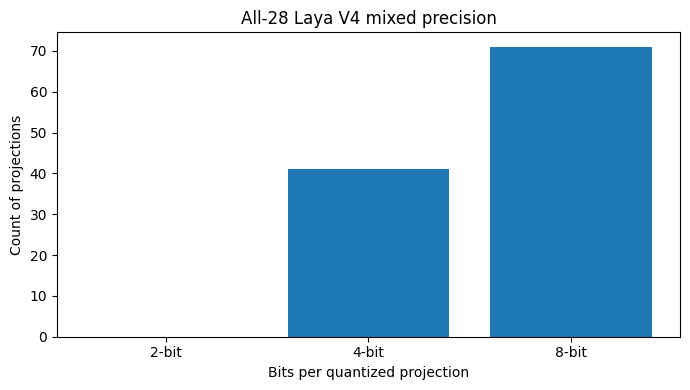

In [13]:
#@title 13. Visualize compression and precision mix
import matplotlib.pyplot as plt
bit_mix=Counter(selected_bits.values())
fig,ax=plt.subplots(figsize=(7,4))
ax.bar([str(b)+"-bit" for b in (2,4,8)],
       [bit_mix.get(b,0) for b in (2,4,8)])
ax.set(xlabel="Bits per quantized projection",ylabel="Count of projections",
       title="All-28 Laya V4 mixed precision")
fig.tight_layout()
fig.savefig(OUT/"precision_mix_v4.png",dpi=160)
plt.show()


In [14]:
#@title 14. Export diagnostics ZIP separately from large packed delta
archive=OUT/"Laya_All28_MixedBit_Sparse_V4_Results.zip"
with zipfile.ZipFile(archive,"w",zipfile.ZIP_DEFLATED) as z:
    for f in OUT.iterdir():
        if f.is_file() and f!=archive and f!=packed_delta_file:
            z.write(f,f.name)
print("Download diagnostics ZIP:",archive)
if SAVE_PACKED_DELTA:
    print("Large packed delta saved separately:",packed_delta_file)
try:
    from google.colab import files
    files.download(str(archive))
except ImportError:pass


Download diagnostics ZIP: /content/Laya_All28_MixedBit_Sparse_V4/Laya_All28_MixedBit_Sparse_V4_Results.zip
Large packed delta saved separately: /content/Laya_All28_MixedBit_Sparse_V4/laya_all28_mixedbit_sparse_v4_delta.safetensors


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Validation and next iteration

This notebook forcibly quantizes all 112 encoder projections but preserves fidelity by beginning with INT8 and sparse outlier corrections. Only development-tested INT4/ternary upgrades are kept. Disjoint audit and official test are opened **once** after selection.

No model is published automatically. The compressed delta needs the precise original source-model SHA and corresponding runtime. The native FP16 runtime path intentionally drops compressed buffers to avoid V3's nearly 2× GPU weight residency; it does **not** provide low-bit compute.

Inspect `summary_sparse_v4.json`, `sparse_recovery.csv`, `precision_trials_v4.csv`, and `latency_v4.csv` before further changes. The notebook's quality, speed and production flags are evidence-based rather than guaranteed improvements.
